<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 50%, #0f3460 100%); padding: 40px; border-radius: 15px; text-align: center; margin-bottom: 20px;">
  <h1 style="color: #e94560; font-size: 2.2em; margin-bottom: 10px;">🛡️ Détection de Spam d'URLs</h1>
  <h2 style="color: #ffffff; font-size: 1.4em; margin-bottom: 15px;">Régression Logistique — Dataset ISCX-URL-2016</h2>
  <p style="color: #a8b2d8; font-size: 1em;">Projet Universitaire · Machine Learning · Classification Binaire</p>
</div>

---

## 📌 1. Introduction

### Contexte

Les URLs malveillantes constituent l'une des principales menaces de cybersécurité. Chaque jour, des millions d'URLs de spam sont diffusées pour tromper les utilisateurs, voler des données ou distribuer des logiciels malveillants.

### Objectif du projet

Ce notebook présente la construction d'un modèle de **classification binaire** capable de détecter automatiquement si une URL est du **spam** ou non, à partir de caractéristiques numériques extraites de chaque URL.

| Classe | Label | Description |
|--------|-------|-------------|
| **Spam** | **1** | URL de spam |
| **Non-Spam** | **0** | Bénigne, Phishing, Malware, Défacement |

### Algorithme utilisé
**Régression Logistique** : un classifieur linéaire simple, interprétable et efficace pour la classification binaire.

### Plan du notebook

| Étape | Section |
|-------|---------|
| 1 | Introduction |
| 2 | Description du dataset |
| 3 | Analyse Exploratoire (EDA) |
| 4 | Prétraitement des données |
| 5 | Entraînement du modèle |
| 6 | Test du modèle |
| 7 | Évaluation du modèle |
| 8 | Optimisation (GridSearchCV) |
| 9 | ⚖️ Équilibrage des classes (SMOTE) |
| 10 | Conclusion |

---

In [1]:
# ═══════════════════════════════════════════════════════════
#  IMPORTATION DES BIBLIOTHÈQUES
# ═══════════════════════════════════════════════════════════

# Manipulation des données
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Prétraitement
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler

# Modèle
from sklearn.linear_model import LogisticRegression

# Évaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, roc_auc_score
)

# ─── Configuration visuelle ───────────────────────────────
sns.set_theme(style='whitegrid', font_scale=1.1)
PALETTE   = ['#4C72B0', '#DD8452']   # Bleu = Non-Spam, Orange = Spam
COLOR_MAP = 'Blues'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)

print('✅ Bibliothèques importées avec succès.')

✅ Bibliothèques importées avec succès.


---

## 📂 2. Description du Dataset

### Présentation

Le dataset **ISCX-URL-2016** (Canadian Institute for Cybersecurity) est un jeu de données de référence en cybersécurité. Il contient des milliers d'URLs catégorisées selon leur type, avec des caractéristiques numériques extraites automatiquement.

| Propriété | Valeur |
|-----------|--------|
| **Fichier** | `All.csv` |
| **Colonne cible** | `URL_Type_obf_Type` |
| **Types d'URLs** | Benign, Spam, Phishing, Malware, Defacement |
| **Variables** | Toutes numériques (sauf la cible) |
| **Valeurs manquantes** | Possibles → à traiter |

> 📂 **Prérequis** : Le fichier `All.csv` doit se trouver dans le même répertoire que ce notebook.

In [2]:
# ═══════════════════════════════════════════════════════════
#  CHARGEMENT DU DATASET
# ═══════════════════════════════════════════════════════════

df = pd.read_csv('All.csv')

print('=' * 50)
print('       📊 INFORMATIONS GÉNÉRALES')
print('=' * 50)
print(f'  Nombre de lignes    : {df.shape[0]:,}')
print(f'  Nombre de colonnes  : {df.shape[1]:,}')
print(f'  Taille mémoire      : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')
print('=' * 50)
print()
print('--- Aperçu des 5 premières lignes ---')
df.head()

       📊 INFORMATIONS GÉNÉRALES
  Nombre de lignes    : 36,707
  Nombre de colonnes  : 80
  Taille mémoire      : 24.09 MB

--- Aperçu des 5 premières lignes ---


,Querylength,domain_token_count,path_token_count,avgdomaintokenlen,longdomaintokenlen,avgpathtokenlen,tld,charcompvowels,charcompace,ldl_url,ldl_domain,ldl_path,ldl_filename,ldl_getArg,dld_url,dld_domain,dld_path,dld_filename,dld_getArg,urlLen,domainlength,pathLength,subDirLen,fileNameLen,this.fileExtLen,...,URL_sensitiveWord,URLQueries_variable,spcharUrl,delimeter_Domain,delimeter_path,delimeter_Count,NumberRate_URL,NumberRate_Domain,NumberRate_DirectoryName,NumberRate_FileName,NumberRate_Extension,NumberRate_AfterPath,SymbolCount_URL,SymbolCount_Domain,SymbolCount_Directoryname,SymbolCount_FileName,SymbolCount_Extension,SymbolCount_Afterpath,Entropy_URL,Entropy_Domain,Entropy_DirectoryName,Entropy_Filename,Entropy_Extension,Entropy_Afterpath,URL_Type_obf_Type
0,0,4,5,5.5000,14,4.4000,4,8,3,0,0,0,0,0,0,0,0,0,0,58,25,26,26,13,1,...,0,0,3,0,2,-1,0.0172,0.0000,0.0000,0.0667,1.0000,-1.0000,8,3,2,1,0,-1,0.7263,0.7845,0.8949,0.8506,NaN,-1.0000,Defacement
1,0,4,5,5.5000,14,6.0000,4,12,4,0,0,0,0,0,0,0,0,0,0,66,25,34,34,2,2,...,0,0,4,0,1,-1,0.0000,0.0000,0.0000,0.0000,NaN,-1.0000,8,3,3,0,0,-1,0.6886,0.7845,0.8147,0.8598,0.0000,-1.0000,Defacement
2,0,4,5,5.5000,14,5.8000,4,12,5,0,0,0,0,0,0,0,0,0,0,65,25,33,33,2,2,...,0,0,4,0,1,-1,0.0000,0.0000,0.0000,0.0000,NaN,-1.0000,8,3,3,0,0,-1,0.6950,0.7845,0.8147,0.8019,0.0000,-1.0000,Defacement
3,0,4,12,5.5000,14,5.5000,4,32,16,0,0,0,0,0,0,0,0,0,0,109,25,77,77,2,2,...,0,0,4,0,8,-1,0.0000,0.0000,0.0000,0.0000,NaN,-1.0000,8,3,3,0,0,-1,0.6401,0.7845,0.8147,0.6632,0.0000,-1.0000,Defacement
4,0,4,6,5.5000,14,7.3333,4,18,11,0,0,0,0,0,0,0,0,0,0,81,25,49,49,2,2,...,0,0,4,0,2,-1,0.0000,0.0000,0.0000,0.0000,NaN,-1.0000,8,3,3,0,0,-1,0.6813,0.7845,0.8147,0.8045,0.0000,-1.0000,Defacement


In [3]:
# ─── Types de données et valeurs manquantes ───────────────
print('--- Types de données ---')
print(df.dtypes.value_counts())
print()

print('--- Distribution de la variable cible ---')
print(df['URL_Type_obf_Type'].value_counts())
print()

print('--- Résumé statistique (5 premières colonnes) ---')
df.describe().iloc[:, :5]

--- Types de données ---
int64      58
float64    21
object      1
Name: count, dtype: int64

--- Distribution de la variable cible ---
URL_Type_obf_Type
Defacement    7930
benign        7781
phishing      7586
malware       6712
spam          6698
Name: count, dtype: int64

--- Résumé statistique (5 premières colonnes) ---


,Querylength,domain_token_count,path_token_count,avgdomaintokenlen,longdomaintokenlen
count,36707.0000,36707.0000,36707.0000,36707.0000,36707.0000
mean,21.9081,2.8574,8.9547,5.4017,9.7460
std,94.2807,0.9066,4.2784,1.9869,4.8566
min,0.0000,2.0000,0.0000,1.5000,2.0000
25%,0.0000,2.0000,6.0000,4.0000,6.0000
50%,0.0000,3.0000,8.0000,5.0000,9.0000
75%,19.0000,3.0000,11.0000,6.5000,12.0000
max,1385.0000,19.0000,68.0000,29.5000,63.0000


---

## 🔍 3. Analyse Exploratoire des Données (EDA)

L'**analyse exploratoire** (EDA) nous permet de mieux comprendre la structure du dataset avant d'appliquer tout algorithme de machine learning. Nous allons analyser :
- La distribution des classes
- Les valeurs manquantes
- La distribution des features importantes
- Les corrélations entre variables

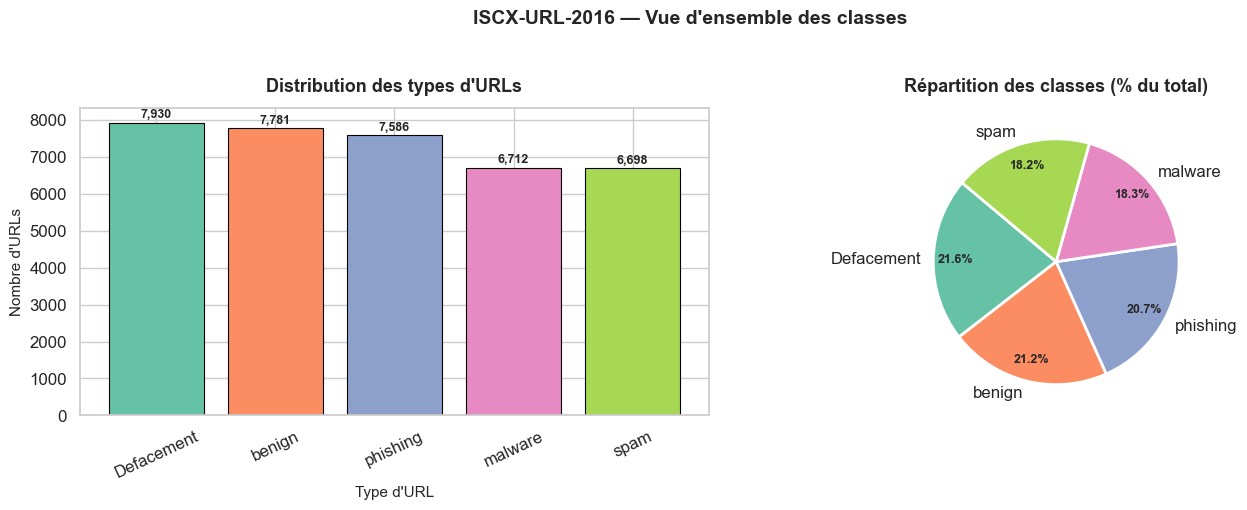

Résumé :
  Defacement      :   7,930 URLs  (21.60%)
  benign          :   7,781 URLs  (21.20%)
  phishing        :   7,586 URLs  (20.67%)
  malware         :   6,712 URLs  (18.29%)
  spam            :   6,698 URLs  (18.25%)


In [4]:
# ═══════════════════════════════════════════════════════════
#  3.1 DISTRIBUTION DES CLASSES ORIGINALES
# ═══════════════════════════════════════════════════════════

class_counts = df['URL_Type_obf_Type'].value_counts()
class_pct    = df['URL_Type_obf_Type'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Barplot ──────────────────────────────────────────────
colors = sns.color_palette('Set2', len(class_counts))
bars = axes[0].bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Distribution des types d\'URLs', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Type d\'URL', fontsize=11)
axes[0].set_ylabel('Nombre d\'URLs', fontsize=11)
axes[0].tick_params(axis='x', rotation=25)
for bar, val in zip(bars, class_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{val:,}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# ── Camembert ─────────────────────────────────────────────
wedges, texts, autotexts = axes[1].pie(
    class_counts.values, labels=class_counts.index,
    autopct='%1.1f%%', colors=colors, startangle=140,
    pctdistance=0.82, wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(9)
    at.set_fontweight('bold')
axes[1].set_title('Répartition des classes (% du total)', fontsize=13, fontweight='bold', pad=12)

plt.suptitle('ISCX-URL-2016 — Vue d\'ensemble des classes', fontsize=14, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

print('Résumé :')
for cls, cnt, pct in zip(class_counts.index, class_counts.values, class_pct.values):
    print(f'  {cls:<15} : {cnt:>7,} URLs  ({pct:.2f}%)')

⚠️  9 colonne(s) avec des valeurs manquantes :


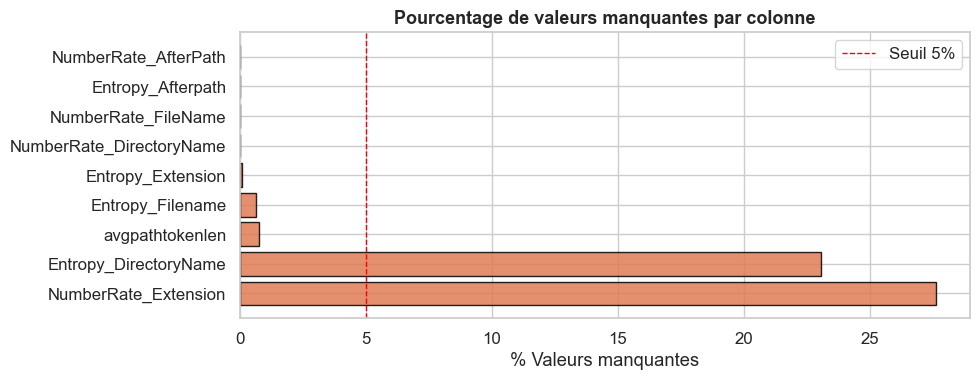

                          Manquants  % Manquants
NumberRate_Extension          10130      27.5969
Entropy_DirectoryName          8468      23.0692
avgpathtokenlen                 280       0.7628
Entropy_Filename                236       0.6429
Entropy_Extension                40       0.1090
NumberRate_DirectoryName         10       0.0272
NumberRate_FileName              10       0.0272
Entropy_Afterpath                 6       0.0163
NumberRate_AfterPath              3       0.0082


In [5]:
# ═══════════════════════════════════════════════════════════
#  3.2 ANALYSE DES VALEURS MANQUANTES
# ═══════════════════════════════════════════════════════════

missing_counts = df.isnull().sum()
missing_pct    = (missing_counts / len(df)) * 100
missing_df     = pd.DataFrame({'Manquants': missing_counts, '% Manquants': missing_pct})
missing_df     = missing_df[missing_df['Manquants'] > 0].sort_values('% Manquants', ascending=False)

if missing_df.empty:
    print('✅ Aucune valeur manquante détectée dans le dataset.')
else:
    print(f'⚠️  {len(missing_df)} colonne(s) avec des valeurs manquantes :')
    top_missing = missing_df.head(20)
    
    fig, ax = plt.subplots(figsize=(10, max(4, len(top_missing) * 0.4)))
    ax.barh(top_missing.index, top_missing['% Manquants'], color='#E07B54', edgecolor='black', alpha=0.85)
    ax.set_title('Pourcentage de valeurs manquantes par colonne', fontsize=13, fontweight='bold')
    ax.set_xlabel('% Valeurs manquantes')
    ax.axvline(5, color='red', linestyle='--', linewidth=1, label='Seuil 5%')
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(missing_df.head(10).to_string())

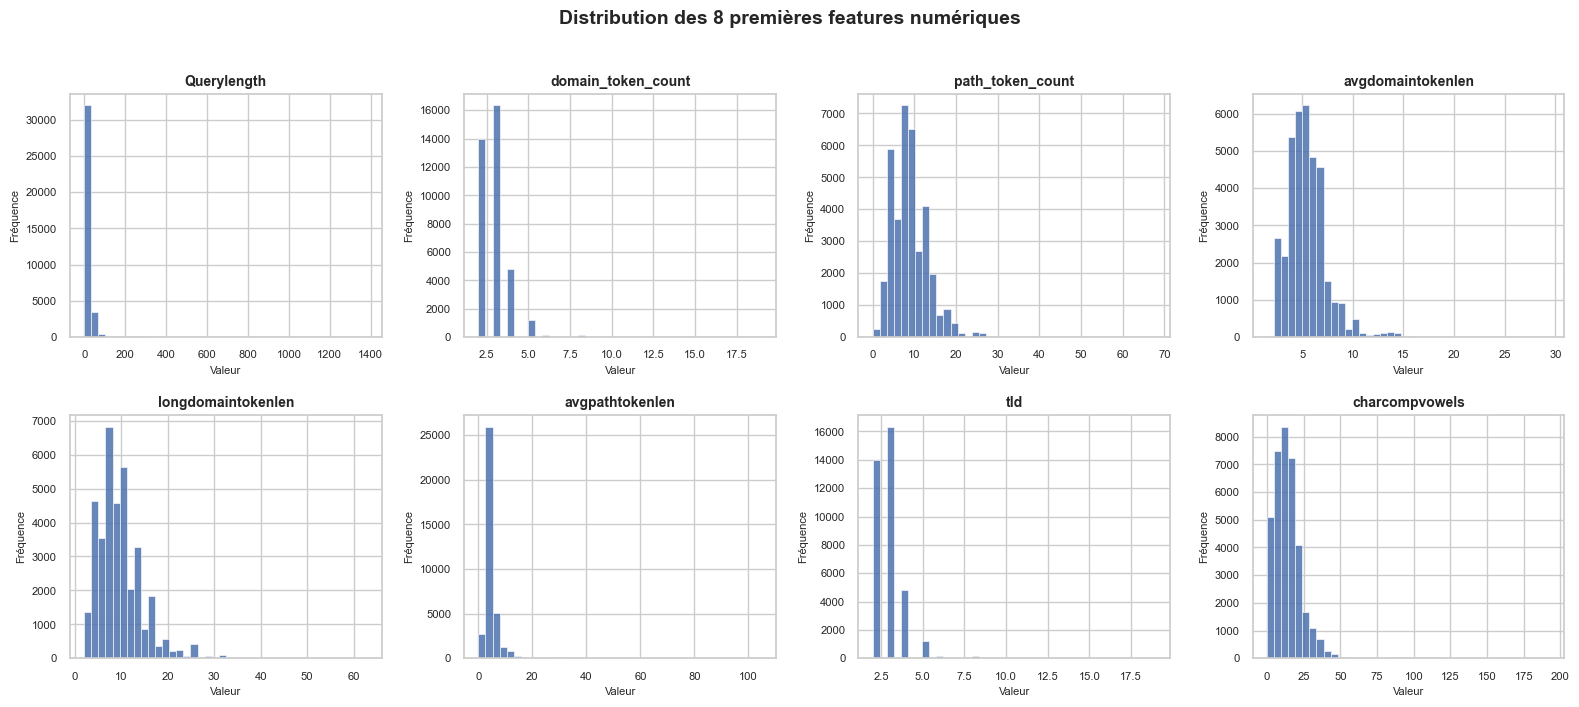

In [6]:
# ═══════════════════════════════════════════════════════════
#  3.3 DISTRIBUTION DES FEATURES NUMÉRIQUES
# ═══════════════════════════════════════════════════════════

# Sélection des 8 premières features numériques pour l'affichage
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
display_cols = numeric_cols[:8]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, col in enumerate(display_cols):
    axes[i].hist(df[col].dropna(), bins=40, color='#4C72B0', edgecolor='white', linewidth=0.5, alpha=0.85)
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Valeur', fontsize=8)
    axes[i].set_ylabel('Fréquence', fontsize=8)
    axes[i].tick_params(labelsize=8)

plt.suptitle('Distribution des 8 premières features numériques', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

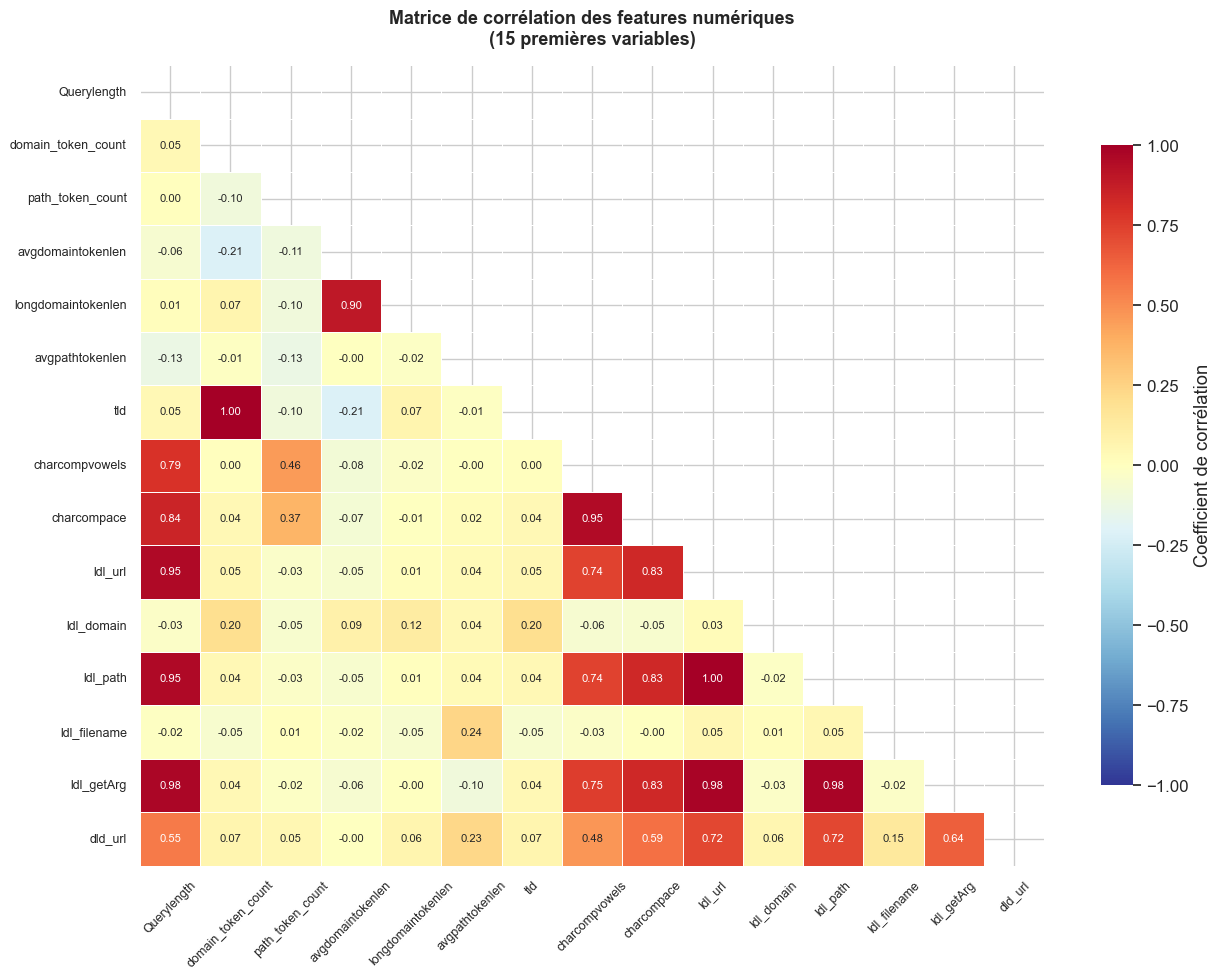

ℹ️  Une corrélation proche de 1 ou -1 indique une forte relation linéaire entre deux variables.
   Des corrélations très élevées peuvent indiquer une redondance dans les features.


In [7]:
# ═══════════════════════════════════════════════════════════
#  3.4 HEATMAP DE CORRÉLATION
# ═══════════════════════════════════════════════════════════

# On limite aux 15 premières features pour la lisibilité
corr_cols = numeric_cols[:15]
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # Masquer le triangle supérieur

sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f',
    cmap='RdYlBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.5, linecolor='white',
    annot_kws={'size': 8}, ax=ax,
    cbar_kws={'shrink': 0.8, 'label': 'Coefficient de corrélation'}
)
ax.set_title('Matrice de corrélation des features numériques\n(15 premières variables)',
             fontsize=13, fontweight='bold', pad=15)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)

plt.tight_layout()
plt.show()

print('ℹ️  Une corrélation proche de 1 ou -1 indique une forte relation linéaire entre deux variables.')
print('   Des corrélations très élevées peuvent indiquer une redondance dans les features.')

---

## ⚙️ 4. Prétraitement des Données

Le prétraitement est une étape **cruciale** avant tout entraînement. Nous allons :

1. **Remplacer les valeurs infinies** par NaN
2. **Encoder la cible** en binaire (Spam = 1 / Non-Spam = 0)
3. **Séparer features et cible** (X et y)
4. **Diviser en train/test** (80% / 20%)
5. **Imputer les valeurs manquantes** par la médiane, calculée **uniquement sur le train** (robuste aux outliers, sans fuite de données)
6. **Normaliser avec StandardScaler**

In [8]:
# ═══════════════════════════════════════════════════════════
#  4.1 TRAITEMENT DES VALEURS INFINIES
# ═══════════════════════════════════════════════════════════

df_clean = df.copy()   # On travaille sur une copie

num_cols = df_clean.select_dtypes(include=[np.number]).columns

# ── Remplacer les valeurs infinies par NaN ────────────────
inf_avant = np.isinf(df_clean[num_cols]).sum().sum()
df_clean[num_cols] = df_clean[num_cols].replace([np.inf, -np.inf], np.nan)
print(f'Valeurs infinies (inf / -inf) remplacées par NaN : {inf_avant:,}')
print(f'Valeurs manquantes (NaN) à imputer               : {df_clean[num_cols].isnull().sum().sum():,}')
print()
print('ℹ️  Les NaN seront remplacés par la médiane APRÈS la séparation train/test (étape 4.5),')
print('   la médiane étant calculée uniquement sur le train pour éviter toute fuite de données.')

Valeurs infinies (inf / -inf) remplacées par NaN : 10


Valeurs manquantes (NaN) à imputer               : 19,193

ℹ️  Les NaN seront remplacés par la médiane APRÈS la séparation train/test (étape 4.5),
   la médiane étant calculée uniquement sur le train pour éviter toute fuite de données.


Distribution des labels binaires :
  Non-Spam (0) : 30,009  (81.8%)
  Spam     (1) : 6,698  (18.2%)


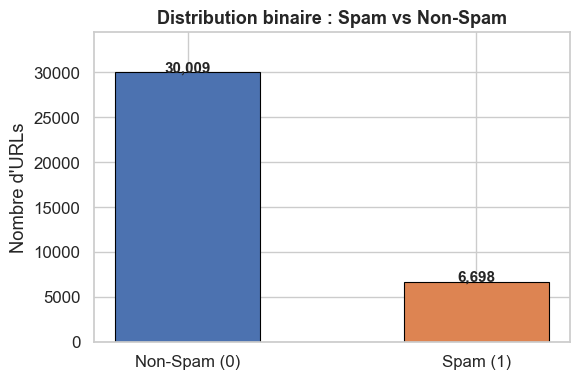

In [9]:
# ═══════════════════════════════════════════════════════════
#  4.2 ENCODAGE BINAIRE DE LA CIBLE
# ═══════════════════════════════════════════════════════════

# Spam → 1,  tout le reste → 0
df_clean['label'] = df_clean['URL_Type_obf_Type'].apply(
    lambda x: 1 if str(x).strip().lower() == 'spam' else 0
)

label_counts = df_clean['label'].value_counts()
print('Distribution des labels binaires :')
print(f'  Non-Spam (0) : {label_counts.get(0, 0):,}  ({label_counts.get(0, 0)/len(df_clean)*100:.1f}%)')
print(f'  Spam     (1) : {label_counts.get(1, 0):,}  ({label_counts.get(1, 0)/len(df_clean)*100:.1f}%)')

# ── Visualisation du déséquilibre ────────────────────────
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Non-Spam (0)', 'Spam (1)'],
              [label_counts.get(0, 0), label_counts.get(1, 0)],
              color=PALETTE, edgecolor='black', linewidth=0.8, width=0.5)
ax.set_title('Distribution binaire : Spam vs Non-Spam', fontsize=13, fontweight='bold')
ax.set_ylabel('Nombre d\'URLs')
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            f'{int(bar.get_height()):,}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(0, max(label_counts.values) * 1.15)
plt.tight_layout()
plt.show()

In [10]:
# ═══════════════════════════════════════════════════════════
#  4.3 SÉPARATION FEATURES / CIBLE
# ═══════════════════════════════════════════════════════════

# Colonnes à exclure des features
cols_a_exclure = ['URL_Type_obf_Type', 'label']

# Supprimer aussi les colonnes texte non numériques (ex : URL brute)
cols_texte = df_clean.select_dtypes(include='object').columns.tolist()
cols_texte = [c for c in cols_texte if c not in cols_a_exclure]
if cols_texte:
    print(f'ℹ️  Colonnes texte supprimées des features : {cols_texte}')
    cols_a_exclure.extend(cols_texte)

X = df_clean.drop(columns=cols_a_exclure)   # Features
y = df_clean['label']                        # Cible

print(f'✅ Séparation effectuée.')
print(f'   Forme de X (features) : {X.shape}')
print(f'   Forme de y (cible)    : {y.shape}')
print(f'   Nombre de features    : {X.shape[1]}')

✅ Séparation effectuée.
   Forme de X (features) : (36707, 79)
   Forme de y (cible)    : (36707,)
   Nombre de features    : 79


In [11]:
# ═══════════════════════════════════════════════════════════
#  4.4 SÉPARATION TRAIN / TEST  (80% / 20%)
# ═══════════════════════════════════════════════════════════

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size   = 0.20,
    random_state= 42,
    stratify    = y    # Préserver la proportion des classes dans chaque split
)

print(f'📦 Ensemble d\'entraînement : {X_train.shape[0]:,} échantillons ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'🔬 Ensemble de test        : {X_test.shape[0]:,} échantillons ({X_test.shape[0]/len(X)*100:.0f}%)')
print()
print('Distribution dans Train :')
print(y_train.value_counts().to_string())
print()
print('Distribution dans Test  :')
print(y_test.value_counts().to_string())

# ═══════════════════════════════════════════════════════════
#  4.5 IMPUTATION DES VALEURS MANQUANTES (médiane du train)
# ═══════════════════════════════════════════════════════════

# IMPORTANT : la médiane est calculée uniquement sur le train,
# puis appliquée au train ET au test (pas de fuite de données)
medianes_train = X_train.median()

nan_avant = X_train.isnull().sum().sum() + X_test.isnull().sum().sum()
X_train = X_train.fillna(medianes_train)
X_test  = X_test.fillna(medianes_train)
nan_apres = X_train.isnull().sum().sum() + X_test.isnull().sum().sum()

print()
print(f'Valeurs manquantes (NaN) AVANT imputation : {nan_avant:,}')
print(f'Valeurs manquantes (NaN) APRÈS imputation : {nan_apres:,}')
print('✅ NaN remplacés par la médiane calculée sur le train.')
print('   Pourquoi la médiane ? Elle est robuste aux valeurs aberrantes (outliers),')
print('   contrairement à la moyenne qui peut être biaisée par des valeurs extrêmes.')

📦 Ensemble d'entraînement : 29,365 échantillons (80%)
🔬 Ensemble de test        : 7,342 échantillons (20%)

Distribution dans Train :
label
0    24007
1     5358

Distribution dans Test  :
label
0    6002
1    1340



Valeurs manquantes (NaN) AVANT imputation : 19,193
Valeurs manquantes (NaN) APRÈS imputation : 0
✅ NaN remplacés par la médiane calculée sur le train.
   Pourquoi la médiane ? Elle est robuste aux valeurs aberrantes (outliers),
   contrairement à la moyenne qui peut être biaisée par des valeurs extrêmes.


In [12]:
# ═══════════════════════════════════════════════════════════
#  4.6 NORMALISATION : StandardScaler
# ═══════════════════════════════════════════════════════════

scaler = StandardScaler()

# IMPORTANT : on fit uniquement sur les données d'entraînement
# pour éviter la fuite de données (data leakage)
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)        # Seulement transform !

print('✅ Normalisation StandardScaler appliquée.')
print()
print('Vérification (1ère feature) :')
print(f'  Moyenne (train) : {X_train_sc[:, 0].mean():.8f}  → doit être ≈ 0')
print(f'  Écart-type      : {X_train_sc[:, 0].std():.8f}  → doit être ≈ 1')
print()
print('ℹ️  Le StandardScaler centre les données (μ=0) et les réduit (σ=1).')
print('   Cela est indispensable pour la Régression Logistique qui est sensible à l\'échelle.')

✅ Normalisation StandardScaler appliquée.

Vérification (1ère feature) :
  Moyenne (train) : -0.00000000  → doit être ≈ 0
  Écart-type      : 1.00000000  → doit être ≈ 1

ℹ️  Le StandardScaler centre les données (μ=0) et les réduit (σ=1).
   Cela est indispensable pour la Régression Logistique qui est sensible à l'échelle.


---

## 🧠 5. Entraînement du Modèle

### La Régression Logistique

La **Régression Logistique** est un algorithme de classification qui modélise la **probabilité** qu'un exemple appartienne à la classe 1 (Spam) via la fonction sigmoïde :

$$P(y=1 \mid X) = \sigma(\mathbf{w}^T X + b) = \frac{1}{1 + e^{-(\mathbf{w}^T X + b)}}$$

### Paramètres clés

| Paramètre | Description | Valeur |
|-----------|-------------|--------|
| `C` | Force de régularisation inverse (grand C = moins de régularisation) | 1.0 |
| `penalty` | Type de régularisation pour éviter le surapprentissage | `l2` |
| `solver` | Algorithme d'optimisation | `lbfgs` |
| `max_iter` | Nombre max d'itérations pour la convergence | 1000 |

In [13]:
# ═══════════════════════════════════════════════════════════
#  ENTRAÎNEMENT DU MODÈLE DE BASE
# ═══════════════════════════════════════════════════════════

modele = LogisticRegression(
    C           = 1.0,
    penalty     = 'l2',
    solver      = 'lbfgs',
    max_iter    = 1000,   # Augmenté pour éviter les problèmes de convergence
    random_state= 42
)

modele.fit(X_train_sc, y_train)

print('✅ Modèle entraîné avec succès !')
print()
print('Paramètres du modèle :')
print(f'  C (régularisation) : {modele.C}')
print(f'  Pénalité           : {modele.penalty}')
print(f'  Solveur            : {modele.solver}')
print(f'  Convergé en        : {modele.n_iter_[0]} itérations')

✅ Modèle entraîné avec succès !

Paramètres du modèle :
  C (régularisation) : 1.0
  Pénalité           : l2
  Solveur            : lbfgs
  Convergé en        : 160 itérations


---

## 🔬 6. Test du Modèle

Nous appliquons le modèle entraîné sur les **données de test** (jamais vues pendant l'entraînement) pour obtenir :

- Les **prédictions de classes** : `predict()` → 0 ou 1
- Les **probabilités** : `predict_proba()` → probabilité d'être Spam

=== Aperçu des 10 premières prédictions ===
    Réel   Prédit  Proba Spam (%) Correct ?
Non-Spam Non-Spam         33.0800         ✅
Non-Spam Non-Spam          0.0400         ✅
Non-Spam Non-Spam          0.0600         ✅
Non-Spam Non-Spam          0.0000         ✅
Non-Spam Non-Spam          1.5800         ✅
Non-Spam Non-Spam          0.3000         ✅
Non-Spam Non-Spam          0.0700         ✅
Non-Spam Non-Spam         12.5200         ✅
Non-Spam Non-Spam          0.0000         ✅
Non-Spam Non-Spam          3.1100         ✅


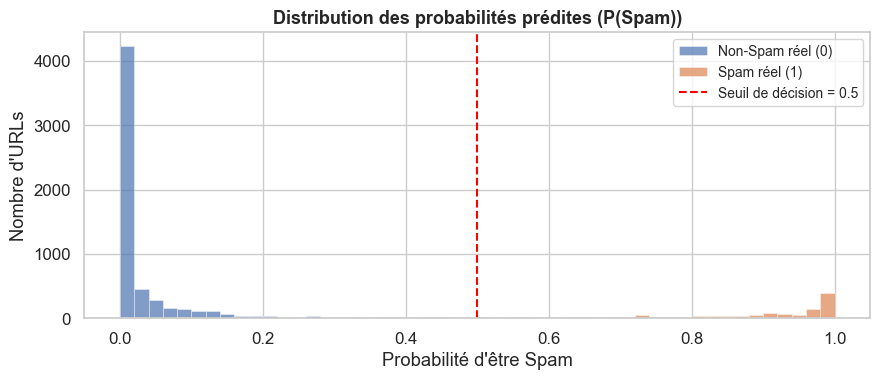

ℹ️  Un bon modèle sépare clairement les deux distributions : Non-Spam vers 0, Spam vers 1.


In [14]:
# ═══════════════════════════════════════════════════════════
#  PRÉDICTIONS SUR LE JEU DE TEST
# ═══════════════════════════════════════════════════════════

y_pred       = modele.predict(X_test_sc)
y_pred_proba = modele.predict_proba(X_test_sc)[:, 1]   # Probabilité d'être Spam (classe 1)

# ── Affichage des 10 premières prédictions ────────────────
print('=== Aperçu des 10 premières prédictions ===')
apercu = pd.DataFrame({
    'Réel'             : y_test.values[:10],
    'Prédit'           : y_pred[:10],
    'Proba Spam (%)'   : (y_pred_proba[:10] * 100).round(2)
})
apercu['Réel']   = apercu['Réel'].map({0: 'Non-Spam', 1: 'Spam'})
apercu['Prédit'] = apercu['Prédit'].map({0: 'Non-Spam', 1: 'Spam'})
apercu['Correct ?'] = apercu['Réel'] == apercu['Prédit']
apercu['Correct ?'] = apercu['Correct ?'].map({True: '✅', False: '❌'})

print(apercu.to_string(index=False))

# ── Distribution des probabilités prédites ────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(y_pred_proba[y_test == 0], bins=50, alpha=0.7, color=PALETTE[0],
        label='Non-Spam réel (0)', edgecolor='white', linewidth=0.4)
ax.hist(y_pred_proba[y_test == 1], bins=50, alpha=0.7, color=PALETTE[1],
        label='Spam réel (1)', edgecolor='white', linewidth=0.4)
ax.axvline(0.5, color='red', linestyle='--', linewidth=1.5, label='Seuil de décision = 0.5')
ax.set_title('Distribution des probabilités prédites (P(Spam))', fontsize=13, fontweight='bold')
ax.set_xlabel('Probabilité d\'être Spam')
ax.set_ylabel('Nombre d\'URLs')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

print('ℹ️  Un bon modèle sépare clairement les deux distributions : Non-Spam vers 0, Spam vers 1.')

---

## 📊 7. Évaluation du Modèle

### Métriques d'évaluation

| Métrique | Formule | Description |
|----------|---------|-------------|
| **Accuracy** | (TP+TN) / Total | Proportion de prédictions correctes |
| **Précision** | TP / (TP+FP) | Parmi les Spam détectés, combien sont vrais ? |
| **Rappel** | TP / (TP+FN) | Parmi tous les vrais Spam, combien détectés ? |
| **F1-Score** | 2×(Prec×Rec)/(Prec+Rec) | Équilibre entre précision et rappel |

> 🎯 En détection de spam, le **Rappel** est prioritaire : il faut minimiser les Spam non détectés (faux négatifs).

In [15]:
# ═══════════════════════════════════════════════════════════
#  7.1 MÉTRIQUES DE CLASSIFICATION
# ═══════════════════════════════════════════════════════════

acc   = accuracy_score(y_test, y_pred)
prec  = precision_score(y_test, y_pred, zero_division=0)
rec   = recall_score(y_test, y_pred, zero_division=0)
f1    = f1_score(y_test, y_pred, zero_division=0)

print('╔══════════════════════════════════════════╗')
print('║      RÉSULTATS — MODÈLE DE BASE          ║')
print('╠══════════════════════════════════════════╣')
print(f'║  Accuracy  (Exactitude)  :  {acc:.4f}     ║')
print(f'║  Precision (Précision)   :  {prec:.4f}     ║')
print(f'║  Recall    (Rappel)      :  {rec:.4f}     ║')
print(f'║  F1-Score                :  {f1:.4f}     ║')
print('╚══════════════════════════════════════════╝')
print()
print('=== Rapport de classification détaillé ===')
print(classification_report(y_test, y_pred, target_names=['Non-Spam (0)', 'Spam (1)']))

╔══════════════════════════════════════════╗
║      RÉSULTATS — MODÈLE DE BASE          ║
╠══════════════════════════════════════════╣
║  Accuracy  (Exactitude)  :  0.9594     ║
║  Precision (Précision)   :  0.9008     ║
║  Recall    (Rappel)      :  0.8739     ║
║  F1-Score                :  0.8871     ║
╚══════════════════════════════════════════╝

=== Rapport de classification détaillé ===
              precision    recall  f1-score   support

Non-Spam (0)       0.97      0.98      0.98      6002
    Spam (1)       0.90      0.87      0.89      1340

    accuracy                           0.96      7342
   macro avg       0.94      0.93      0.93      7342
weighted avg       0.96      0.96      0.96      7342



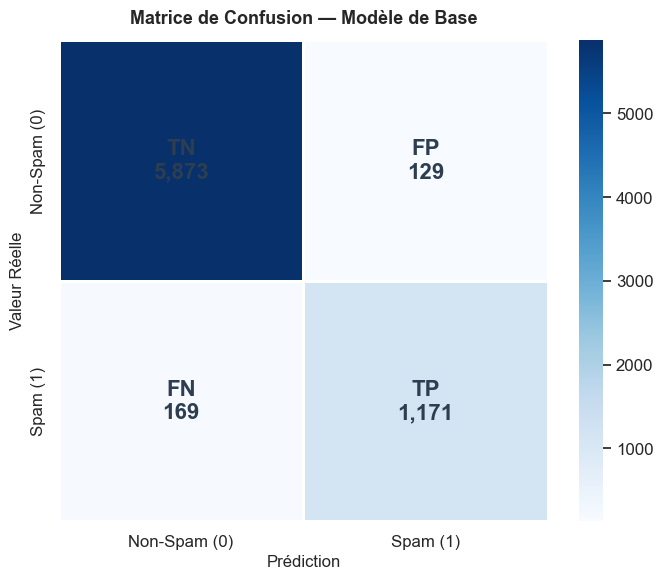

  Vrais Négatifs  (TN) — Non-Spam correctement détecté : 5,873
  Faux Positifs   (FP) — Non-Spam classé comme Spam    : 129
  Faux Négatifs   (FN) — Spam non détecté              : 169
  Vrais Positifs  (TP) — Spam correctement détecté     : 1,171


In [16]:
# ═══════════════════════════════════════════════════════════
#  7.2 MATRICE DE CONFUSION
# ═══════════════════════════════════════════════════════════

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7, 6))

# Affichage de la heatmap
sns.heatmap(
    cm, annot=False, cmap='Blues',
    xticklabels=['Non-Spam (0)', 'Spam (1)'],
    yticklabels=['Non-Spam (0)', 'Spam (1)'],
    linewidths=2, linecolor='white', ax=ax
)

# Annotations personnalisées avec étiquettes
labels_cm = [[f'TN\n{tn:,}', f'FP\n{fp:,}'],
             [f'FN\n{fn:,}', f'TP\n{tp:,}']]
colors_cm = [['#d4e6f1', '#fadbd8'], ['#fadbd8', '#d5f5e3']]

for i in range(2):
    for j in range(2):
        ax.text(j + 0.5, i + 0.5, labels_cm[i][j],
                ha='center', va='center', fontsize=16, fontweight='bold',
                color='#2c3e50')

ax.set_title('Matrice de Confusion — Modèle de Base', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Prédiction', fontsize=12)
ax.set_ylabel('Valeur Réelle', fontsize=12)
plt.tight_layout()
plt.show()

print(f'  Vrais Négatifs  (TN) — Non-Spam correctement détecté : {tn:,}')
print(f'  Faux Positifs   (FP) — Non-Spam classé comme Spam    : {fp:,}')
print(f'  Faux Négatifs   (FN) — Spam non détecté              : {fn:,}')
print(f'  Vrais Positifs  (TP) — Spam correctement détecté     : {tp:,}')

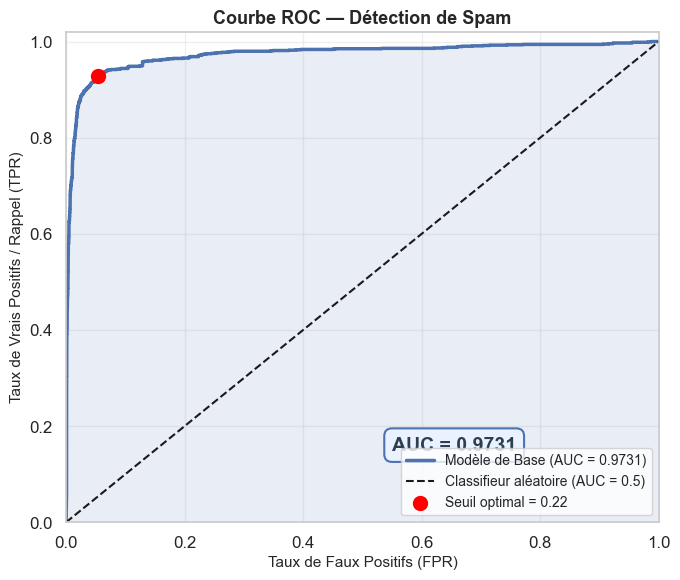

📈 Score AUC : 0.9731
   Seuil optimal : 0.2198

ℹ️  Un AUC > 0.9 indique un modèle très performant.
   Un AUC = 1.0 représente un classifieur parfait.
   Un AUC = 0.5 représente un classifieur aléatoire (sans valeur).


In [17]:
# ═══════════════════════════════════════════════════════════
#  7.3 COURBE ROC ET SCORE AUC
# ═══════════════════════════════════════════════════════════

fpr, tpr, seuils = roc_curve(y_test, y_pred_proba)
auc_score        = roc_auc_score(y_test, y_pred_proba)

# Trouver le point optimal (maximise TPR - FPR)
idx_optimal = np.argmax(tpr - fpr)
seuil_opt   = seuils[idx_optimal]

fig, ax = plt.subplots(figsize=(7, 6))

# Remplissage sous la courbe
ax.fill_between(fpr, tpr, alpha=0.12, color='#4C72B0')

# Courbe ROC
ax.plot(fpr, tpr, color='#4C72B0', lw=2.5,
        label=f'Modèle de Base (AUC = {auc_score:.4f})')

# Classifier aléatoire
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Classifieur aléatoire (AUC = 0.5)')

# Point optimal
ax.scatter(fpr[idx_optimal], tpr[idx_optimal], color='red', s=100, zorder=5,
           label=f'Seuil optimal = {seuil_opt:.2f}')

ax.set_title('Courbe ROC — Détection de Spam', fontsize=13, fontweight='bold')
ax.set_xlabel('Taux de Faux Positifs (FPR)', fontsize=11)
ax.set_ylabel('Taux de Vrais Positifs / Rappel (TPR)', fontsize=11)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
ax.grid(True, alpha=0.3)

# Annotation AUC
ax.text(0.55, 0.15, f'AUC = {auc_score:.4f}', fontsize=14,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#eaf2ff', edgecolor='#4C72B0', linewidth=1.5),
        color='#2c3e50', fontweight='bold')

plt.tight_layout()
plt.show()

print(f'📈 Score AUC : {auc_score:.4f}')
print(f'   Seuil optimal : {seuil_opt:.4f}')
print()
print('ℹ️  Un AUC > 0.9 indique un modèle très performant.')
print('   Un AUC = 1.0 représente un classifieur parfait.')
print('   Un AUC = 0.5 représente un classifieur aléatoire (sans valeur).')

### 🔎 Interprétation des résultats

**Analyse du modèle de base :**

- **Accuracy (95,9 %)** : le modèle classe correctement la grande majorité des URLs. Ce chiffre est flatteur à cause du déséquilibre des classes : prédire toujours « Non-Spam » donnerait déjà 81,8 %.

- **Précision (90,1 %)** : lorsque le modèle prédit « Spam », il a raison dans environ 90 % des cas (129 fausses alarmes sur 7 342 URLs de test).

- **Rappel (87,4 %)** : le modèle détecte environ 87 % des vrais Spam ; 169 Spam passent inaperçus. C'est la métrique la plus critique en sécurité.

- **F1-Score (0,887)** : bon équilibre entre précision et rappel.

- **AUC (0,973)** : le modèle sépare très bien les deux classes, tous seuils confondus. Le seuil optimal de la courbe ROC (≈ 0,22) est bien plus bas que 0,5 : baisser le seuil augmenterait le rappel.

> ⚙️ Dans la prochaine section, nous allons **optimiser** ces résultats via GridSearchCV.

---

## ⚙️ 8. Optimisation — GridSearchCV

### Principe de GridSearchCV

**GridSearchCV** effectue une recherche exhaustive dans une grille de paramètres et évalue chaque combinaison par **validation croisée** (cross-validation).

Nous allons optimiser :
- **C** : `[0.01, 0.1, 1, 10, 100]` — force de régularisation
- **penalty** : `l1` ou `l2` — type de régularisation
- **solver** : compatible avec chaque pénalité

Métrique cible : **F1-score** (équilibre précision/rappel)

In [18]:
# ═══════════════════════════════════════════════════════════
#  8.1 GRILLE DE PARAMÈTRES
# ═══════════════════════════════════════════════════════════

param_grid = [
    {
        'C'       : [0.01, 0.1, 1, 10, 100],
        'penalty' : ['l2'],
        'solver'  : ['lbfgs', 'liblinear']
    },
    {
        'C'       : [0.01, 0.1, 1, 10, 100],
        'penalty' : ['l1'],
        'solver'  : ['liblinear']   # l1 uniquement compatible avec liblinear
    }
]

# ─── Lancement de la recherche ────────────────────────────
grid_search = GridSearchCV(
    estimator  = LogisticRegression(max_iter=1000, random_state=42),
    param_grid = param_grid,
    cv         = 5,         # Validation croisée 5 blocs
    scoring    = 'f1',      # Optimiser le F1-Score
    n_jobs     = -1,        # Utiliser tous les cœurs CPU
    verbose    = 1
)

print('🔍 Lancement de GridSearchCV...')
print('   (Recherche sur', sum(len(pg.get('C', [])) * len(pg.get('penalty', [])) * len(pg.get('solver', [])) for pg in param_grid), 'combinaisons × 5 folds)')
print()

grid_search.fit(X_train_sc, y_train)

print()
print('✅ Recherche terminée !')
print(f'   Meilleurs paramètres  : {grid_search.best_params_}')
print(f'   Meilleur F1 (CV)      : {grid_search.best_score_:.4f}')

🔍 Lancement de GridSearchCV...
   (Recherche sur 15 combinaisons × 5 folds)

Fitting 5 folds for each of 15 candidates, totalling 75 fits



✅ Recherche terminée !
   Meilleurs paramètres  : {'C': 100, 'penalty': 'l1', 'solver': 'liblinear'}
   Meilleur F1 (CV)      : 0.8982


In [19]:
# ═══════════════════════════════════════════════════════════
#  8.2 TABLEAU DES RÉSULTATS DE LA GRILLE
# ═══════════════════════════════════════════════════════════

resultats_cv = pd.DataFrame(grid_search.cv_results_)
colonnes = ['param_C', 'param_penalty', 'param_solver',
            'mean_test_score', 'std_test_score', 'rank_test_score']
tableau_top = (resultats_cv[colonnes]
               .sort_values('rank_test_score')
               .head(10)
               .reset_index(drop=True))
tableau_top.columns = ['C', 'Pénalité', 'Solveur', 'F1 Moyen (CV)', 'Écart-Type', 'Rang']

print('=== Top 10 des combinaisons de paramètres ===')
print(tableau_top.to_string(index=False))

=== Top 10 des combinaisons de paramètres ===
       C Pénalité   Solveur  F1 Moyen (CV)  Écart-Type  Rang
100.0000       l1 liblinear         0.8982      0.0073     1
 10.0000       l1 liblinear         0.8974      0.0072     2
100.0000       l2     lbfgs         0.8965      0.0073     3
100.0000       l2 liblinear         0.8961      0.0076     4
 10.0000       l2 liblinear         0.8938      0.0071     5
 10.0000       l2     lbfgs         0.8931      0.0071     6
  1.0000       l1 liblinear         0.8930      0.0090     7
  1.0000       l2 liblinear         0.8879      0.0105     8
  1.0000       l2     lbfgs         0.8876      0.0109     9
  0.1000       l1 liblinear         0.8726      0.0095    10


In [20]:
# ═══════════════════════════════════════════════════════════
#  8.3 ÉVALUATION DU MODÈLE OPTIMISÉ
# ═══════════════════════════════════════════════════════════

meilleur_modele = grid_search.best_estimator_

# Prédictions avec le meilleur modèle
y_pred_opt       = meilleur_modele.predict(X_test_sc)
y_pred_proba_opt = meilleur_modele.predict_proba(X_test_sc)[:, 1]

acc_opt  = accuracy_score(y_test, y_pred_opt)
prec_opt = precision_score(y_test, y_pred_opt, zero_division=0)
rec_opt  = recall_score(y_test, y_pred_opt, zero_division=0)
f1_opt   = f1_score(y_test, y_pred_opt, zero_division=0)
auc_opt  = roc_auc_score(y_test, y_pred_proba_opt)

print('╔══════════════════════════════════════════════╗')
print('║       RÉSULTATS — MODÈLE OPTIMISÉ            ║')
print('╠══════════════════════════════════════════════╣')
print(f'║  Accuracy  (Exactitude)  :  {acc_opt:.4f}       ║')
print(f'║  Precision (Précision)   :  {prec_opt:.4f}       ║')
print(f'║  Recall    (Rappel)      :  {rec_opt:.4f}       ║')
print(f'║  F1-Score                :  {f1_opt:.4f}       ║')
print(f'║  AUC Score               :  {auc_opt:.4f}       ║')
print('╚══════════════════════════════════════════════╝')
print()
print('=== Rapport de classification — Modèle optimisé ===')
print(classification_report(y_test, y_pred_opt, target_names=['Non-Spam (0)', 'Spam (1)']))

╔══════════════════════════════════════════════╗
║       RÉSULTATS — MODÈLE OPTIMISÉ            ║
╠══════════════════════════════════════════════╣
║  Accuracy  (Exactitude)  :  0.9613       ║
║  Precision (Précision)   :  0.9037       ║
║  Recall    (Rappel)      :  0.8821       ║
║  F1-Score                :  0.8927       ║
║  AUC Score               :  0.9750       ║
╚══════════════════════════════════════════════╝

=== Rapport de classification — Modèle optimisé ===
              precision    recall  f1-score   support

Non-Spam (0)       0.97      0.98      0.98      6002
    Spam (1)       0.90      0.88      0.89      1340

    accuracy                           0.96      7342
   macro avg       0.94      0.93      0.93      7342
weighted avg       0.96      0.96      0.96      7342



=== Comparaison Modèle de Base vs. Modèle Optimisé ===
 Métrique  Modèle de Base  Modèle Optimisé Amélioration
 Accuracy          0.9594           0.9613    +0.0019 ✅
Précision          0.9008           0.9037    +0.0029 ✅
   Rappel          0.8739           0.8821    +0.0082 ✅
 F1-Score          0.8871           0.8927    +0.0056 ✅
      AUC          0.9731           0.9750    +0.0018 ✅


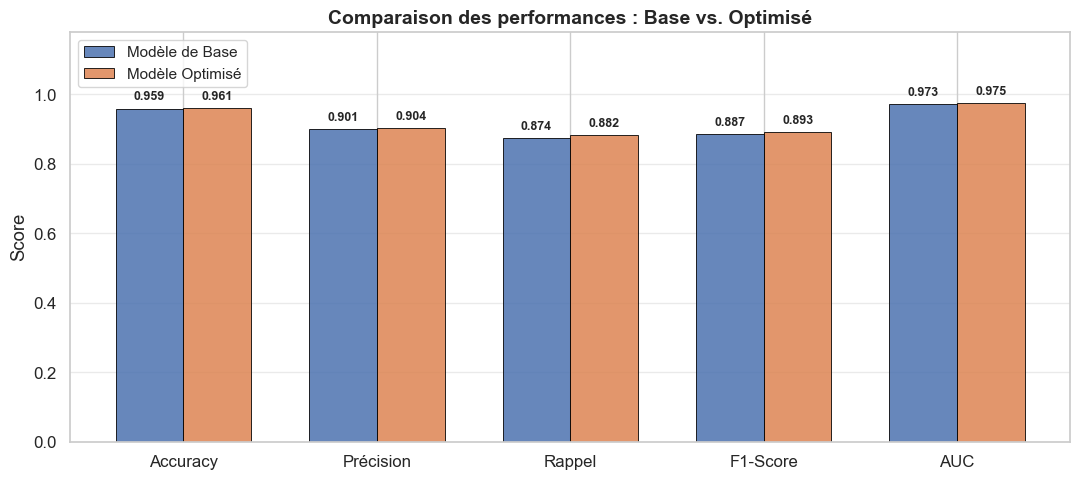

In [21]:
# ═══════════════════════════════════════════════════════════
#  8.4 COMPARAISON AVANT / APRÈS OPTIMISATION
# ═══════════════════════════════════════════════════════════

# Tableau comparatif
tableau_comp = pd.DataFrame({
    'Métrique'         : ['Accuracy', 'Précision', 'Rappel', 'F1-Score', 'AUC'],
    'Modèle de Base'   : [acc,  prec,  rec,  f1,  auc_score],
    'Modèle Optimisé'  : [acc_opt, prec_opt, rec_opt, f1_opt, auc_opt]
})
tableau_comp['Amélioration'] = (tableau_comp['Modèle Optimisé'] - tableau_comp['Modèle de Base'])
tableau_comp['Amélioration'] = tableau_comp['Amélioration'].apply(
    lambda x: f'+{x:.4f} ✅' if x > 0 else (f'{x:.4f} ❌' if x < 0 else f'0.0000 ➖')
)

print('=== Comparaison Modèle de Base vs. Modèle Optimisé ===')
print(tableau_comp.to_string(index=False))

# ── Graphique de comparaison ──────────────────────────────
metriques  = ['Accuracy', 'Précision', 'Rappel', 'F1-Score', 'AUC']
scores_base = [acc,  prec,  rec,  f1,  auc_score]
scores_opt  = [acc_opt, prec_opt, rec_opt, f1_opt, auc_opt]

x     = np.arange(len(metriques))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

bars1 = ax.bar(x - width/2, scores_base, width, label='Modèle de Base',
               color='#4C72B0', edgecolor='black', linewidth=0.7, alpha=0.85)
bars2 = ax.bar(x + width/2, scores_opt,  width, label='Modèle Optimisé',
               color='#DD8452', edgecolor='black', linewidth=0.7, alpha=0.85)

ax.set_title('Comparaison des performances : Base vs. Optimisé', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_xticks(x)
ax.set_xticklabels(metriques)
ax.set_ylim(0, 1.18)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.4)

for bar in list(bars1) + list(bars2):
    ax.annotate(f'{bar.get_height():.3f}',
                xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

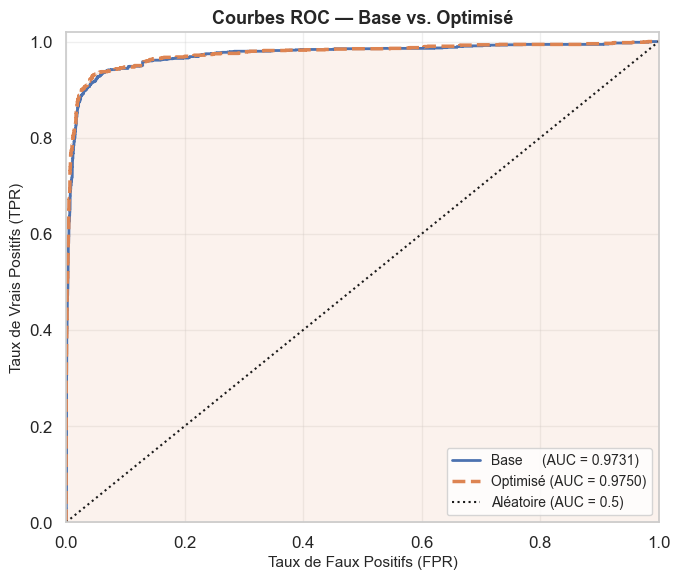

In [22]:
# ═══════════════════════════════════════════════════════════
#  8.5 COURBES ROC SUPERPOSÉES
# ═══════════════════════════════════════════════════════════

fpr_opt, tpr_opt, _ = roc_curve(y_test, y_pred_proba_opt)

fig, ax = plt.subplots(figsize=(7, 6))

ax.fill_between(fpr_opt, tpr_opt, alpha=0.10, color='#DD8452')
ax.plot(fpr,     tpr,     color='#4C72B0', lw=2,   label=f'Base     (AUC = {auc_score:.4f})')
ax.plot(fpr_opt, tpr_opt, color='#DD8452', lw=2.5, linestyle='--',
        label=f'Optimisé (AUC = {auc_opt:.4f})')
ax.plot([0, 1],  [0, 1],  'k:',  lw=1.5, label='Aléatoire (AUC = 0.5)')

ax.set_title('Courbes ROC — Base vs. Optimisé', fontsize=13, fontweight='bold')
ax.set_xlabel('Taux de Faux Positifs (FPR)', fontsize=11)
ax.set_ylabel('Taux de Vrais Positifs (TPR)', fontsize=11)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

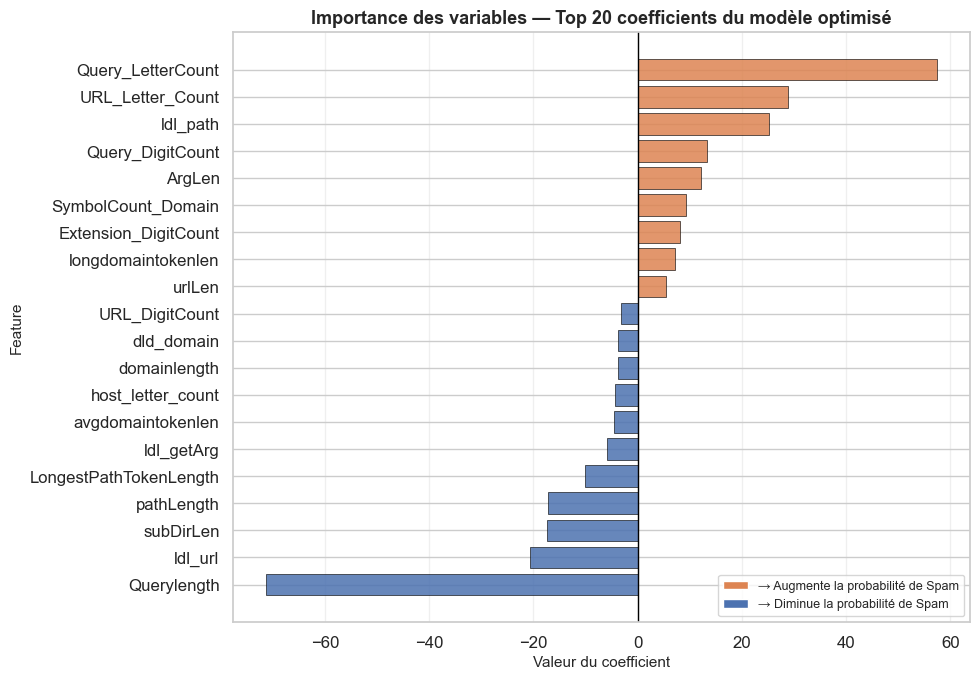

=== Top 10 features les plus influentes ===
               Feature  Coefficient
           Querylength     -71.2561
     Query_LetterCount      57.3975
      URL_Letter_Count      28.9156
              ldl_path      25.2423
               ldl_url     -20.6359
             subDirLen     -17.4945
            pathLength     -17.2696
      Query_DigitCount      13.3672
                ArgLen      12.2164
LongestPathTokenLength     -10.1975


In [23]:
# ═══════════════════════════════════════════════════════════
#  8.6 IMPORTANCE DES VARIABLES (COEFFICIENTS)
# ═══════════════════════════════════════════════════════════

noms_features  = X.columns.tolist()
coefficients   = meilleur_modele.coef_[0]

imp_df = pd.DataFrame({
    'Feature'     : noms_features,
    'Coefficient' : coefficients
}).sort_values('Coefficient', key=abs, ascending=False)

top_n     = min(20, len(imp_df))
top_feats = imp_df.head(top_n).copy()
top_feats = top_feats.sort_values('Coefficient')   # Pour un affichage horizontal lisible

couleurs = ['#DD8452' if c > 0 else '#4C72B0' for c in top_feats['Coefficient']]

fig, ax = plt.subplots(figsize=(10, 7))
barras = ax.barh(top_feats['Feature'], top_feats['Coefficient'],
                 color=couleurs, edgecolor='black', linewidth=0.5, alpha=0.85)

ax.axvline(x=0, color='black', linewidth=1)
ax.set_title(f'Importance des variables — Top {top_n} coefficients du modèle optimisé',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Valeur du coefficient', fontsize=11)
ax.set_ylabel('Feature', fontsize=11)

legend_elements = [
    mpatches.Patch(facecolor='#DD8452', label='→ Augmente la probabilité de Spam'),
    mpatches.Patch(facecolor='#4C72B0', label='→ Diminue la probabilité de Spam')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print(f'=== Top 10 features les plus influentes ===')
print(imp_df.head(10).to_string(index=False))

=== Validation croisée 5-folds (F1-Score) ===
  Fold 1 : 0.8946
  Fold 2 : 0.8911
  Fold 3 : 0.9052
  Fold 4 : 0.8917
  Fold 5 : 0.9086
  ─────────────────────────────
  Moyenne  : 0.8982
  Écart-type : 0.0073


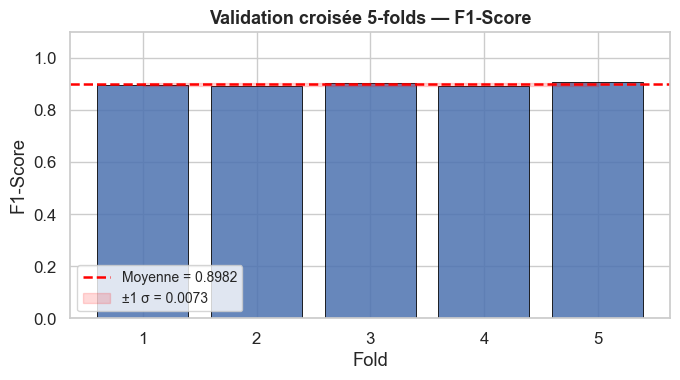

In [24]:
# ═══════════════════════════════════════════════════════════
#  8.7 VALIDATION CROISÉE SUR LE MODÈLE OPTIMISÉ
# ═══════════════════════════════════════════════════════════

scores_cv = cross_val_score(meilleur_modele, X_train_sc, y_train, cv=5, scoring='f1', n_jobs=-1)

print('=== Validation croisée 5-folds (F1-Score) ===')
for i, s in enumerate(scores_cv, 1):
    print(f'  Fold {i} : {s:.4f}')
print(f'  ─────────────────────────────')
print(f'  Moyenne  : {scores_cv.mean():.4f}')
print(f'  Écart-type : {scores_cv.std():.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, 6), scores_cv, color='#4C72B0', edgecolor='black', linewidth=0.7, alpha=0.85)
ax.axhline(scores_cv.mean(), color='red', linestyle='--', lw=1.8,
           label=f'Moyenne = {scores_cv.mean():.4f}')
ax.fill_between(range(1, 6),
                scores_cv.mean() - scores_cv.std(),
                scores_cv.mean() + scores_cv.std(),
                alpha=0.15, color='red', label=f'±1 σ = {scores_cv.std():.4f}')
ax.set_title('Validation croisée 5-folds — F1-Score', fontsize=13, fontweight='bold')
ax.set_xlabel('Fold')
ax.set_ylabel('F1-Score')
ax.set_xticks(range(1, 6))
ax.set_ylim(0, 1.1)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

---

## ⚖️ 9. Équilibrage des Classes — SMOTE

### 9.1 Pourquoi équilibrer les classes ?

Notre dataset présente un **déséquilibre significatif** :

| Classe | Effectif | Proportion |
|--------|----------|------------|
| Non-Spam (0) | ~30 009 | **81.8 %** |
| Spam (1)     | ~6 698  | **18.2 %** |

Ce déséquilibre pose un problème fondamental : un modèle peut atteindre **81.8% d'accuracy** en prédisant *toujours* Non-Spam, sans jamais apprendre à détecter le Spam. Le **Rappel** (recall) de la classe Spam sera alors très faible.

### 9.2 Principe de SMOTE

**SMOTE** (Synthetic Minority Over-sampling Technique) crée des exemples **synthétiques** de la classe minoritaire (Spam) en interpolant entre des exemples réels proches dans l'espace des features :

```
Nouvel exemple = x_i + λ × (x_voisin - x_i)   où λ ∈ [0, 1] aléatoire
```

| Technique | Mécanisme | Risque |
|-----------|-----------|--------|
| **Duplication** (Random Over-sampling) | Copie exacte d'exemples Spam | Overfitting sur les mêmes exemples |
| **SMOTE** | Génère de nouveaux exemples interpolés | Plus robuste, moins d'overfitting |
| **class_weight** | Pénalise plus les erreurs sur la minorité | Pas de nouveaux exemples créés |

> ⚠️ **Règle cruciale** : SMOTE s'applique **uniquement sur les données d'entraînement**, jamais sur le test. Sinon on introduit une fuite de données (data leakage).

---

In [25]:
# ═══════════════════════════════════════════════════════════
#  9.3 INSTALLATION ET IMPORT DE IMBALANCED-LEARN
# ═══════════════════════════════════════════════════════════

# Installation si nécessaire (décommenter si besoin)
# !pip install imbalanced-learn --quiet

from imblearn.over_sampling import SMOTE

print('✅ imbalanced-learn importé avec succès.')
print(f'   Version : ', end='')
import imblearn
print(imblearn.__version__)

✅ imbalanced-learn importé avec succès.
   Version : 0.14.1


=== Distribution AVANT SMOTE (train) ===
  Non-Spam (0) : 24,007  (81.8%)
  Spam     (1) : 5,358  (18.2%)
  Total        : 29,365



=== Distribution APRÈS SMOTE (train) ===
  Non-Spam (0) : 24,007  (50.0%)
  Spam     (1) : 24,007  (50.0%)
  Total        : 48,014

  Nouveaux exemples Spam synthétiques créés : 18,649

⚠️  SMOTE appliqué UNIQUEMENT sur X_train_sc — X_test_sc reste intact.


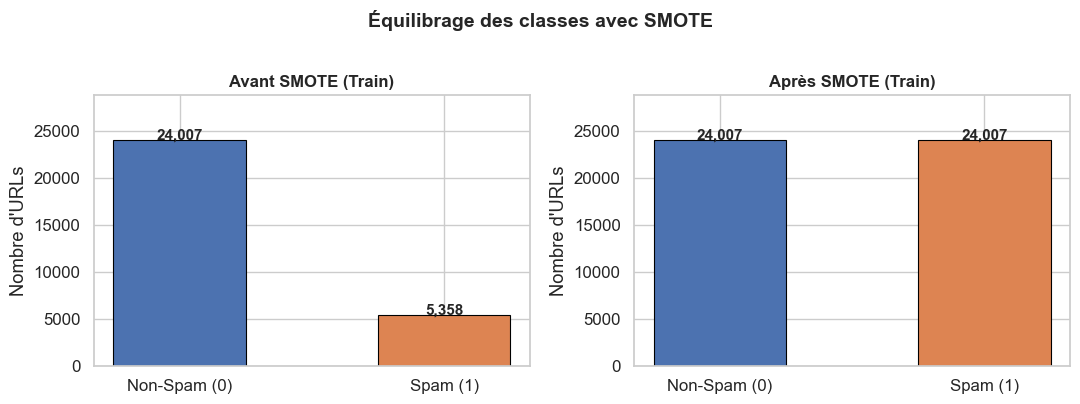

In [26]:
# ═══════════════════════════════════════════════════════════
#  9.4 APPLICATION DE SMOTE SUR LES DONNÉES D'ENTRAÎNEMENT
# ═══════════════════════════════════════════════════════════

# Distribution AVANT SMOTE
print('=== Distribution AVANT SMOTE (train) ===')
print(f'  Non-Spam (0) : {(y_train == 0).sum():,}  ({(y_train == 0).mean()*100:.1f}%)')
print(f'  Spam     (1) : {(y_train == 1).sum():,}  ({(y_train == 1).mean()*100:.1f}%)')
print(f'  Total        : {len(y_train):,}')
print()

# Application de SMOTE
# k_neighbors=5 (défaut) : chaque exemple minoritaire est interpolé avec ses 5 plus proches voisins
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = smote.fit_resample(X_train_sc, y_train)

# Distribution APRÈS SMOTE
print('=== Distribution APRÈS SMOTE (train) ===')
print(f'  Non-Spam (0) : {(y_train_sm == 0).sum():,}  ({(y_train_sm == 0).mean()*100:.1f}%)')
print(f'  Spam     (1) : {(y_train_sm == 1).sum():,}  ({(y_train_sm == 1).mean()*100:.1f}%)')
print(f'  Total        : {len(y_train_sm):,}')
print()
print(f'  Nouveaux exemples Spam synthétiques créés : {(y_train_sm == 1).sum() - (y_train == 1).sum():,}')
print()
print('⚠️  SMOTE appliqué UNIQUEMENT sur X_train_sc — X_test_sc reste intact.')

# ── Visualisation avant / après ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, counts, title in zip(
    axes,
    [y_train.value_counts(), pd.Series(y_train_sm).value_counts()],
    ['Avant SMOTE (Train)', 'Après SMOTE (Train)']
):
    bars = ax.bar(
        ['Non-Spam (0)', 'Spam (1)'],
        [counts.get(0, 0), counts.get(1, 0)],
        color=PALETTE, edgecolor='black', linewidth=0.8, width=0.5
    )
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 100,
            f'{int(bar.get_height()):,}',
            ha='center', fontsize=11, fontweight='bold'
        )
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel("Nombre d'URLs")
    ax.set_ylim(0, max(counts.values) * 1.2)

plt.suptitle('Équilibrage des classes avec SMOTE', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [27]:
# ═══════════════════════════════════════════════════════════
#  9.5 ENTRAÎNEMENT DU MODÈLE AVEC SMOTE
# ═══════════════════════════════════════════════════════════

# Reprendre les meilleurs paramètres trouvés par GridSearchCV
modele_smote = LogisticRegression(
    C           = grid_search.best_params_['C'],
    penalty     = grid_search.best_params_['penalty'],
    solver      = grid_search.best_params_['solver'],
    max_iter    = 1000,
    random_state= 42
)

# Entraînement sur les données SMOTE
modele_smote.fit(X_train_sm, y_train_sm)

# Prédictions sur le TEST ORIGINAL (non rééchantillonné)
y_pred_sm       = modele_smote.predict(X_test_sc)
y_pred_proba_sm = modele_smote.predict_proba(X_test_sc)[:, 1]

# Métriques
acc_sm  = accuracy_score(y_test, y_pred_sm)
prec_sm = precision_score(y_test, y_pred_sm, zero_division=0)
rec_sm  = recall_score(y_test, y_pred_sm, zero_division=0)
f1_sm   = f1_score(y_test, y_pred_sm, zero_division=0)
auc_sm  = roc_auc_score(y_test, y_pred_proba_sm)

print('╔══════════════════════════════════════════════════╗')
print('║     RÉSULTATS — MODÈLE SMOTE + OPTIMISÉ          ║')
print('╠══════════════════════════════════════════════════╣')
print(f'║  Accuracy  (Exactitude)  :  {acc_sm:.4f}           ║')
print(f'║  Precision (Précision)   :  {prec_sm:.4f}           ║')
print(f'║  Recall    (Rappel)      :  {rec_sm:.4f}           ║')
print(f'║  F1-Score                :  {f1_sm:.4f}           ║')
print(f'║  AUC Score               :  {auc_sm:.4f}           ║')
print('╚══════════════════════════════════════════════════╝')
print()
print(classification_report(y_test, y_pred_sm, target_names=['Non-Spam (0)', 'Spam (1)']))

╔══════════════════════════════════════════════════╗
║     RÉSULTATS — MODÈLE SMOTE + OPTIMISÉ          ║
╠══════════════════════════════════════════════════╣
║  Accuracy  (Exactitude)  :  0.9350           ║
║  Precision (Précision)   :  0.7561           ║
║  Recall    (Rappel)      :  0.9507           ║
║  F1-Score                :  0.8423           ║
║  AUC Score               :  0.9756           ║
╚══════════════════════════════════════════════════╝

              precision    recall  f1-score   support

Non-Spam (0)       0.99      0.93      0.96      6002
    Spam (1)       0.76      0.95      0.84      1340

    accuracy                           0.94      7342
   macro avg       0.87      0.94      0.90      7342
weighted avg       0.95      0.94      0.94      7342



=== Comparaison complète des 3 modèles ===
 Métrique  Modèle de Base  Optimisé (Grid)  SMOTE + Optimisé SMOTE vs Base
 Accuracy          0.9594           0.9613            0.9350     -0.0244 ❌
Précision          0.9008           0.9037            0.7561     -0.1447 ❌
   Rappel          0.8739           0.8821            0.9507     +0.0769 ✅
 F1-Score          0.8871           0.8927            0.8423     -0.0448 ❌
      AUC          0.9731           0.9750            0.9756     +0.0025 ✅



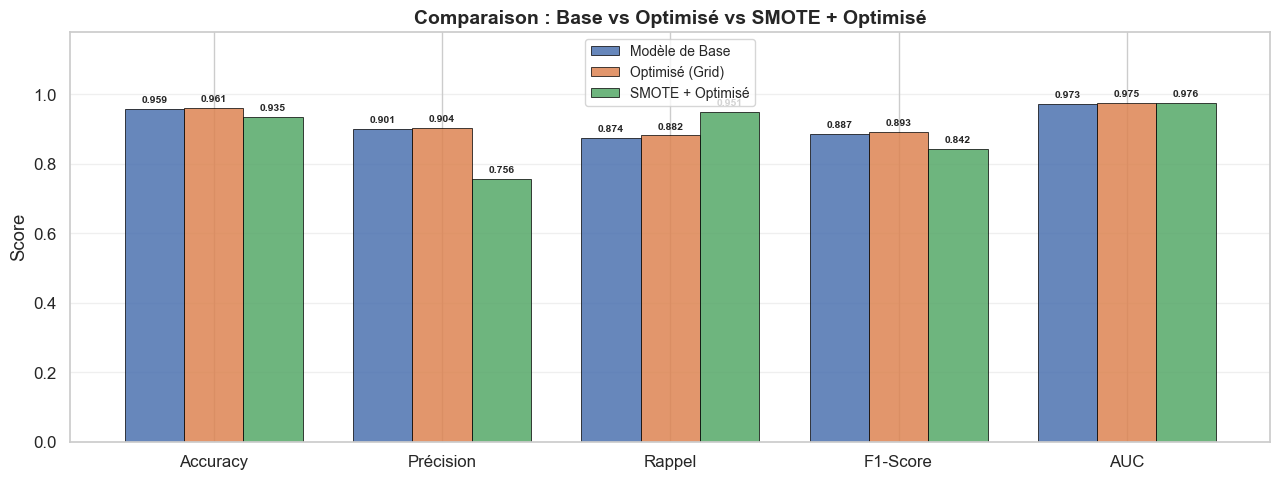

In [28]:
# ═══════════════════════════════════════════════════════════
#  9.6 COMPARAISON COMPLÈTE : BASE / OPTIMISÉ / SMOTE
# ═══════════════════════════════════════════════════════════

# ── Tableau comparatif ───────────────────────────────────
comp3 = pd.DataFrame({
    'Métrique'        : ['Accuracy', 'Précision', 'Rappel', 'F1-Score', 'AUC'],
    'Modèle de Base'  : [acc,      prec,      rec,      f1,      auc_score],
    'Optimisé (Grid)' : [acc_opt,  prec_opt,  rec_opt,  f1_opt,  auc_opt],
    'SMOTE + Optimisé': [acc_sm,   prec_sm,   rec_sm,   f1_sm,   auc_sm],
})
comp3['SMOTE vs Base'] = (comp3['SMOTE + Optimisé'] - comp3['Modèle de Base'])
comp3['SMOTE vs Base'] = comp3['SMOTE vs Base'].apply(
    lambda x: f'+{x:.4f} ✅' if x > 0.0001 else (f'{x:.4f} ❌' if x < -0.0001 else '≈ 0.0000')
)
print('=== Comparaison complète des 3 modèles ===')
print(comp3.to_string(index=False))
print()

# ── Graphique barres groupées ─────────────────────────────
metriques    = ['Accuracy', 'Précision', 'Rappel', 'F1-Score', 'AUC']
scores_base  = [acc,     prec,     rec,     f1,     auc_score]
scores_opt   = [acc_opt, prec_opt, rec_opt, f1_opt, auc_opt]
scores_smote = [acc_sm,  prec_sm,  rec_sm,  f1_sm,  auc_sm]

x     = np.arange(len(metriques))
width = 0.26

fig, ax = plt.subplots(figsize=(13, 5))
b1 = ax.bar(x - width, scores_base,  width, label='Modèle de Base',   color='#4C72B0', edgecolor='black', linewidth=0.6, alpha=0.85)
b2 = ax.bar(x,         scores_opt,   width, label='Optimisé (Grid)',  color='#DD8452', edgecolor='black', linewidth=0.6, alpha=0.85)
b3 = ax.bar(x + width, scores_smote, width, label='SMOTE + Optimisé', color='#55A868', edgecolor='black', linewidth=0.6, alpha=0.85)

ax.set_title('Comparaison : Base vs Optimisé vs SMOTE + Optimisé', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_xticks(x)
ax.set_xticklabels(metriques)
ax.set_ylim(0, 1.18)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

for bars in [b1, b2, b3]:
    for bar in bars:
        ax.annotate(
            f'{bar.get_height():.3f}',
            xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
            xytext=(0, 3), textcoords='offset points',
            ha='center', va='bottom', fontsize=7.5, fontweight='bold'
        )

plt.tight_layout()
plt.show()

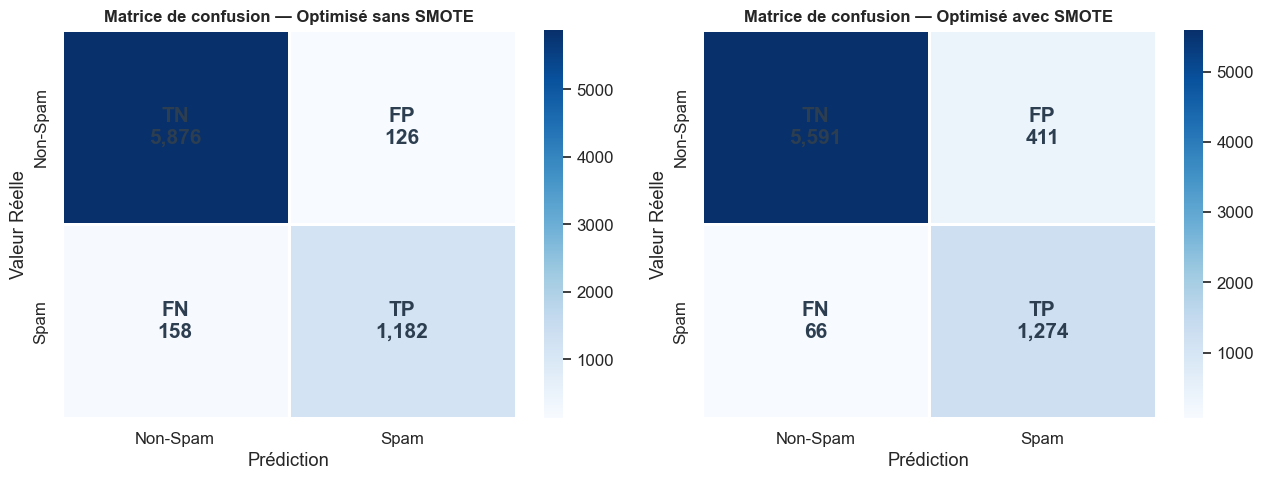

=== Impact de SMOTE sur les erreurs (modèle optimisé) ===
  Faux Négatifs (Spam manqués)    SANS SMOTE : 158
  Faux Négatifs (Spam manqués)    AVEC SMOTE : 66  ✅ Diminué
  Faux Positifs (Fausses alarmes) SANS SMOTE : 126
  Faux Positifs (Fausses alarmes) AVEC SMOTE : 411  ⚠️ Augmenté (compromis rappel / précision)


In [29]:
# ═══════════════════════════════════════════════════════════
#  9.7 MATRICE DE CONFUSION — OPTIMISÉ SANS / AVEC SMOTE
# ═══════════════════════════════════════════════════════════

cm_best = confusion_matrix(y_test, y_pred_opt)
tn_o, fp_o, fn_o, tp_o = cm_best.ravel()

cm_sm = confusion_matrix(y_test, y_pred_sm)
tn_s, fp_s, fn_s, tp_s = cm_sm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, cm_data, title, vals in zip(
    axes,
    [cm_best, cm_sm],
    ['Optimisé sans SMOTE', 'Optimisé avec SMOTE'],
    [(tn_o, fp_o, fn_o, tp_o), (tn_s, fp_s, fn_s, tp_s)]
):
    tn_v, fp_v, fn_v, tp_v = vals
    sns.heatmap(
        cm_data, annot=False, cmap='Blues',
        xticklabels=['Non-Spam', 'Spam'],
        yticklabels=['Non-Spam', 'Spam'],
        linewidths=2, linecolor='white', ax=ax
    )
    labels = [[f'TN\n{tn_v:,}', f'FP\n{fp_v:,}'],
              [f'FN\n{fn_v:,}', f'TP\n{tp_v:,}']]
    for i in range(2):
        for j in range(2):
            ax.text(j+0.5, i+0.5, labels[i][j],
                    ha='center', va='center', fontsize=15,
                    fontweight='bold', color='#2c3e50')
    ax.set_title(f'Matrice de confusion — {title}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Prédiction')
    ax.set_ylabel('Valeur Réelle')

plt.tight_layout()
plt.show()

print('=== Impact de SMOTE sur les erreurs (modèle optimisé) ===')
print(f'  Faux Négatifs (Spam manqués)    SANS SMOTE : {fn_o:,}')
print(f'  Faux Négatifs (Spam manqués)    AVEC SMOTE : {fn_s:,}', end='  ')
print('✅ Diminué' if fn_s < fn_o else '❌ Augmenté')
print(f'  Faux Positifs (Fausses alarmes) SANS SMOTE : {fp_o:,}')
print(f'  Faux Positifs (Fausses alarmes) AVEC SMOTE : {fp_s:,}', end='  ')
print('✅ Diminué' if fp_s < fp_o else '⚠️ Augmenté (compromis rappel / précision)')

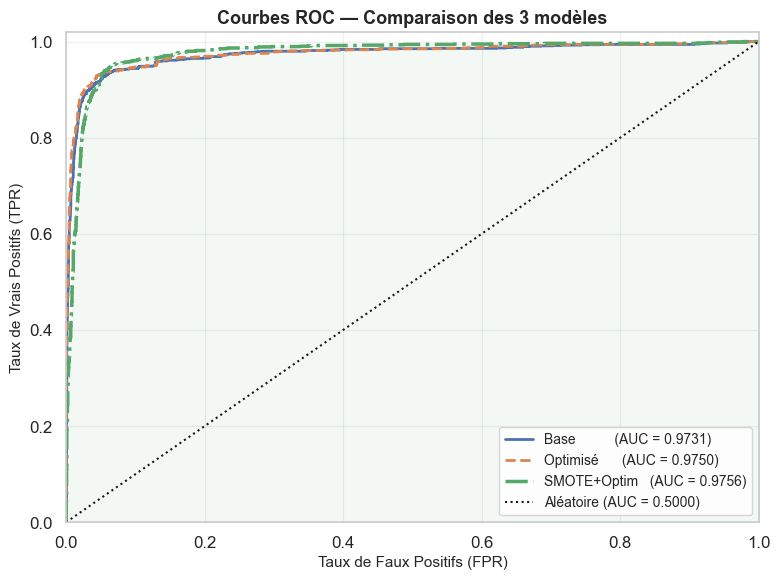

In [30]:
# ═══════════════════════════════════════════════════════════
#  9.8 COURBES ROC — LES 3 MODÈLES SUPERPOSÉES
# ═══════════════════════════════════════════════════════════

fpr_sm, tpr_sm, _ = roc_curve(y_test, y_pred_proba_sm)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(fpr,     tpr,     color='#4C72B0', lw=2,   label=f'Base          (AUC = {auc_score:.4f})')
ax.plot(fpr_opt, tpr_opt, color='#DD8452', lw=2,   linestyle='--', label=f'Optimisé      (AUC = {auc_opt:.4f})')
ax.plot(fpr_sm,  tpr_sm,  color='#55A868', lw=2.5, linestyle='-.',  label=f'SMOTE+Optim   (AUC = {auc_sm:.4f})')
ax.plot([0, 1],  [0, 1],  'k:',  lw=1.5,   label='Aléatoire (AUC = 0.5000)')

ax.fill_between(fpr_sm, tpr_sm, alpha=0.07, color='#55A868')

ax.set_title('Courbes ROC — Comparaison des 3 modèles', fontsize=13, fontweight='bold')
ax.set_xlabel('Taux de Faux Positifs (FPR)', fontsize=11)
ax.set_ylabel('Taux de Vrais Positifs (TPR)', fontsize=11)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 9.9 Interprétation des résultats SMOTE

**Ce que SMOTE change (par rapport au modèle optimisé sans SMOTE) :**

| Aspect | Sans SMOTE | Avec SMOTE | Explication |
|--------|-----------|-----------|-------------|
| **Rappel** | 0,882 | **0,951** ↑ | Le modèle voit beaucoup plus d'exemples Spam → Spam manqués : 158 → 66 |
| **Précision** | 0,904 | **0,756** ↓ | Nette baisse : fausses alarmes 126 → 411 |
| **F1-Score** | 0,893 | **0,842** ↓ | La perte de précision l'emporte sur le gain de rappel |
| **AUC** | 0,975 | **0,976** ≈ | La capacité de séparation du modèle ne change pas |

> 🎯 **Lecture** : l'AUC quasi identique montre que SMOTE ne rend pas le modèle « meilleur » ; il **déplace le compromis** vers plus de rappel et moins de précision, un peu comme baisser le seuil de décision. Si un spam manqué coûte beaucoup plus cher qu'une fausse alarme, le modèle SMOTE est préférable ; sinon le modèle optimisé sans SMOTE reste le meilleur sur le F1.

> ⚠️ **SMOTE ne résout pas tout** : il génère des exemples *entre* des vrais Spam — si la frontière de décision est très complexe, des modèles non-linéaires (Random Forest, XGBoost) seront plus efficaces.

---

---

## 🏁 10. Conclusion

### Récapitulatif du projet

Dans ce notebook, nous avons construit un **système de détection de spam d'URLs** basé sur la **Régression Logistique**, en suivant une démarche complète de machine learning.

### ✅ Étapes réalisées

| Étape | Action | Résultat |
|-------|--------|----------|
| **Prétraitement** | Infinis → NaN, encodage binaire, imputation par la médiane du train | Dataset propre, sans fuite de données |
| **Split** | 80% train / 20% test avec stratification | Distribution préservée |
| **Normalisation** | StandardScaler (fit sur train uniquement) | Features centrées réduites |
| **Entraînement** | LogisticRegression (C=1, l2, lbfgs, 1000 iter) | Modèle convergé |
| **Évaluation** | Accuracy, Précision, Rappel, F1, AUC, Confusion | Métriques complètes |
| **Optimisation** | GridSearchCV (C, penalty, solver) | Meilleurs hyperparamètres |
| **SMOTE** | Sur-échantillonnage synthétique minoritaire | Rappel ↑, précision et F1 ↓ |

### 📌 Points clés d'apprentissage

1. **La Régression Logistique** est un classifieur linéaire rapide, interprétable et efficace pour la classification binaire d'URLs.

2. **Le StandardScaler** est indispensable : sans normalisation, la Régression Logistique peut ne pas converger ou donner de mauvais résultats.

3. **GridSearchCV** permet de trouver les meilleurs hyperparamètres de manière rigoureuse via la validation croisée, évitant l'overfitting.

4. **Le Rappel** est la métrique prioritaire en détection de spam : il vaut mieux quelques fausses alarmes que laisser passer des URLs malveillantes.

5. **L'AUC-ROC** confirme la robustesse du modèle indépendamment du seuil de décision.

6. **SMOTE** génère des exemples synthétiques de la classe minoritaire (Spam) en interpolant entre voisins réels. Il augmente nettement le rappel, mais au prix de beaucoup plus de fausses alarmes : la précision et le F1 baissent. Le choix entre le modèle optimisé et le modèle SMOTE dépend donc du coût d'un spam manqué par rapport à une fausse alarme.

### 🚀 Améliorations possibles

- Tester d'autres algorithmes : **Random Forest**, **SVM**, **Gradient Boosting**
- Ajuster le **seuil de décision** (au lieu de SMOTE) pour choisir le compromis rappel / précision
- Effectuer une sélection de features (éliminer les variables redondantes)
- Déployer le modèle dans une API REST (Flask / FastAPI)

---

<div style="background: #f0f4ff; border-left: 5px solid #4C72B0; padding: 15px; border-radius: 5px;">
<strong>📚 Projet Universitaire — Détection de Spam</strong><br>
Dataset : ISCX-URL-2016 | Algorithme : Régression Logistique | Framework : Scikit-Learn<br>
<em>Notebook réalisé avec Python · pandas · scikit-learn · matplotlib · seaborn</em>
</div>